In [1]:
!pip install transformers[torch] datasets sentencepiece spacy textstat requests fpdf2 evaluate numpy rouge_score

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 81.0/81.0 kB 4.5 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 177.1/177.1 kB 11.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 327.1/327.1 kB 22.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 84.1/84.1 kB 5.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.1/2.1 MB 40.0 MB/s eta 0:00:00
  Created wheel for rouge_score: filename=rouge_score-0.1.2-py3-none-any.whl size=24934 sha256=dfcfe9fdbdafa90f5a5e8ccd55da0631c4477d50eb247fb15caa65aae21401ed
  Stored in directory: /root/.cache/pip/wheels/85/9d/af/01feefbe7d55ef5468796f0c68225b6788e85d9d0a281e7a70
Successfully built rouge_score


In [2]:
!python -m spacy download fr_core_news_sm
!python -m spacy download en_core_web_sm

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 16.3/16.3 MB 57.0 MB/s eta 0:00:00
✔ Download and installation successful
You can now load the package via spacy.load('fr_core_news_sm')
⚠ Restart to reload dependencies
If you are in a Jupyter or Colab notebook, you may need to restart Python in
order to load all the package's dependencies. You can do this by selecting the
'Restart kernel' or 'Restart runtime' option.
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.8/12.8 MB 67.6 MB/s eta 0:00:00
✔ Download and installation successful
You can now load the package via spacy.load('en_core_web_sm')
⚠ Restart to reload dependencies
If you are in a Jupyter or Colab notebook, you may need to restart Python in
order to load all the package's dependencies. You can do this by selecting the
'Restart kernel' or 'Restart runtime' option.


In [ ]:
import json
from datasets import Dataset, DatasetDict
from transformers import T5Tokenizer, T5ForConditionalGeneration, Seq2SeqTrainingArguments, Seq2SeqTrainer, AutoTokenizer, AutoModelForSeq2SeqLM, EarlyStoppingCallback
import spacy
import textstat
import requests
import os
import re
from fpdf import FPDF
import evaluate
import numpy as np
from matplotlib import pyplot as plt

In [ ]:
def compute_metrics(eval_preds):
    preds, labels = eval_preds

    # 1. Décoder les prédictions (on ignore les tokens spéciaux comme <pad>)
    decoded_preds = tokenizer.batch_decode(preds, skip_special_tokens=True)

    # 2. Remplacer -100 dans les labels (utilisé pour ignorer le calcul de la loss) par du padding
    labels = [[(l if l != -100 else tokenizer.pad_token_id) for l in label] for label in labels]
    decoded_labels = tokenizer.batch_decode(labels, skip_special_tokens=True)

    # 3. Calculer les scores Flesch
    # On calcule la moyenne du score sur tout le batch de validation
    flesch_scores = []
    textstat.set_lang('fr')

    for pred in decoded_preds:
        # On évite les chaînes vides qui feraient planter le calcul
        if len(pred.strip()) > 0:
            flesch_scores.append(textstat.flesch_reading_ease(pred))
        else:
            flesch_scores.append(0)

    # Moyenne des scores
    avg_flesch = sum(flesch_scores) / len(flesch_scores)

    return {
        "flesch_reading_ease": avg_flesch
    }

Entrainement sur nos données.

In [ ]:
import json
from datasets import Dataset
from transformers import T5Tokenizer, T5ForConditionalGeneration, Seq2SeqTrainingArguments, Seq2SeqTrainer, DataCollatorForSeq2Seq


with open('../data/custom/data.json', 'r', encoding='utf-8') as f:
    data = json.load(f)

# Conversion au format "Dataset" Hugging Face
dataset = Dataset.from_list(data)
dataset = dataset.shuffle(seed=42)
dataset = dataset.train_test_split(test_size=0.2)

train_dataset   = dataset['train']
test_dataset    = dataset['test']


model_name = "t5-base" #t5-small à l'origine
tokenizer = T5Tokenizer.from_pretrained(model_name)
model = T5ForConditionalGeneration.from_pretrained(model_name)

def preprocess_function(examples):
    inputs = ["Simplifie en falc: " + doc for doc in examples["input"]]
    model_inputs = tokenizer(inputs, max_length=512, truncation=True, padding="max_length") #max length d'origine : 128

    # The as_target_tokenizer() context manager is deprecated. Tokenize targets directly.
    labels = tokenizer(text_target=examples["output"], max_length=256, truncation=True, padding="max_length") #max_length d'origine : 128

    model_inputs["labels"] = labels["input_ids"]
    return model_inputs

train_dataset = train_dataset.map(preprocess_function, batched=True)
test_dataset = test_dataset.map(preprocess_function, batched=True )
data_collator = DataCollatorForSeq2Seq(tokenizer, model=model)

training_args = Seq2SeqTrainingArguments(
    output_dir="../resultats_falc/custom/",
    per_device_train_batch_size=8,
    num_train_epochs=15,
    learning_rate=1e-3,
    save_total_limit=2,
    predict_with_generate=True,
    logging_steps=10,
    fp16=True,
    lr_scheduler_type="cosine",
    weight_decay= 0.01 #0.01,
    #eval_strategy="epoch",  # Pour voir l'évolution à chaque étape
)

# On charge la métrique ROUGE
rouge_metric = evaluate.load("rouge")
def compute_metrics(eval_preds):
    preds, labels = eval_preds


    decoded_preds = tokenizer.batch_decode(preds, skip_special_tokens=True)

    labels = np.where(labels != -100, labels, tokenizer.pad_token_id)
    decoded_labels = tokenizer.batch_decode(labels, skip_special_tokens=True)

    flesch_scores = []
    lix_scores = []
    textstat.set_lang('fr')

    for pred in decoded_preds:
        text = pred.strip()
        if len(text) > 0:
            flesch_scores.append(textstat.flesch_reading_ease(text))
            lix_scores.append(textstat.lix(text))
        else:
            flesch_scores.append(0)
            # Un score LIX élevé signifie un texte dur,
            # mais pour une chaîne vide, on met souvent 0 ou un indicateur nul.
            lix_scores.append(0)

    # Moyennes
    avg_flesch = sum(flesch_scores) / len(flesch_scores) if flesch_scores else 0
    avg_lix = sum(lix_scores) / len(lix_scores) if lix_scores else 0

    rouge_results = rouge_metric.compute(
        predictions=decoded_preds,
        references=decoded_labels,
        use_stemmer=True
    )

    return {
        "flesch_reading_ease": avg_flesch,
        "lix": avg_lix,
        "rouge1": rouge_results["rouge1"],
        "rouge2": rouge_results["rouge2"],
        "rougeL": rouge_results["rougeL"]
    }

trainer = Seq2SeqTrainer(
    model=model,
    args=training_args,
    train_dataset=train_dataset,
    eval_dataset=test_dataset,
    data_collator=data_collator, #
    compute_metrics = compute_metrics
)

print("L'entraînement commence...")
trainer.train()
# 6. Sauvegarde du modèle final
model.save_pretrained("../models/falc")
tokenizer.save_pretrained("../models/falc")
print("Modèle sauvegardé dans le dossier 'models/falc' !")
results = trainer.evaluate(eval_dataset = test_dataset)
print(results)

Xet Storage is enabled for this repo, but the 'hf_xet' package is not installed. Falling back to regular HTTP download. For better performance, install the package with: `pip install huggingface_hub[hf_xet]` or `pip install hf_xet`
Map: 100%|██████████| 96/96 [00:00<00:00, 1867.70 examples/s]


NameError: name 'evaluate' is not defined

<h1>Entrainement à l'aide des données ETR-fr</h1>

In [ ]:
def preprocess_function(examples):
    inputs = ["Simplifie en falc: " + doc for doc in examples["input"]]
    model_inputs = tokenizer(inputs, max_length=512, truncation=True, padding="max_length") #max length d'origine : 128

    # The as_target_tokenizer() context manager is deprecated. Tokenize targets directly.
    labels = tokenizer(text_target=examples["output"], max_length=256, truncation=True, padding="max_length") #max_length d'origine : 128

    model_inputs["labels"] = labels["input_ids"]
    return model_inputs


def train2():
  """
  Entrainement à l'aide des données ETR-fr.
  """

  with open("../data/etr-fr/train.json", 'r') as f:
    train = json.load(f)
    train = Dataset.from_list(train)
  with open("../data/etr-fr/test.json", 'r') as f:
    test = json.load(f)
    test = Dataset.from_list(test)
  with open("../data/etr-fr/val.json", 'r') as f:
    val = json.load(f)
    val = Dataset.from_list(val)

  dataset = DatasetDict({
    'train': train,
    'validation': val,
    'test': test
  })

  model_name = "t5-small"
  tokenizer = T5Tokenizer.from_pretrained(model_name)
  model = T5ForConditionalGeneration.from_pretrained(model_name)

  train_dataset = dataset['train']
  test_dataset = dataset['test']
  val_dataset = dataset['validation']

  def preprocess_function(examples):
    inputs = ["Simplifie en falc: " + doc for doc in examples["input"]]
    model_inputs = tokenizer(inputs, max_length=512, truncation=True, padding="max_length") #max length d'origine : 128

    # The as_target_tokenizer() context manager is deprecated. Tokenize targets directly.
    labels = tokenizer(text_target=examples["output"], max_length=256, truncation=True, padding="max_length") #max_length d'origine : 128

    model_inputs["labels"] = labels["input_ids"]
    return model_inputs
  train_dataset = train_dataset.map(preprocess_function, batched=True)
  test_dataset = test_dataset.map(preprocess_function, batched=True )

  training_args = Seq2SeqTrainingArguments(
      output_dir="../resultats_falc/etr-fr/",
      per_device_train_batch_size=8,
      num_train_epochs=15,
      learning_rate=1e-3,
      lr_scheduler_type="cosine",
      weight_decay= 0.01,
      save_total_limit=2,
      predict_with_generate=True,
      logging_steps=10,
      fp16=True,
      remove_unused_columns=False,
  )

  val_dataset = val_dataset.map(preprocess_function, batched=True)
  import textstat

  # On charge la métrique ROUGE
  rouge_metric = evaluate.load("rouge")

  def compute_metrics(eval_preds):
    preds, labels = eval_preds


    decoded_preds = tokenizer.batch_decode(preds, skip_special_tokens=True)


    labels = np.where(labels != -100, labels, tokenizer.pad_token_id)
    decoded_labels = tokenizer.batch_decode(labels, skip_special_tokens=True)

    flesch_scores = []
    lix_scores = []
    textstat.set_lang('fr')

    for pred in decoded_preds:
        text = pred.strip()
        if len(text) > 0:
            flesch_scores.append(textstat.flesch_reading_ease(text))
            lix_scores.append(textstat.lix(text))
        else:
            flesch_scores.append(0)
            # Un score LIX élevé signifie un texte dur,
            # mais pour une chaîne vide, on met souvent 0 ou un indicateur nul.
            lix_scores.append(0)

    # Moyennes
    avg_flesch = sum(flesch_scores) / len(flesch_scores) if flesch_scores else 0
    avg_lix = sum(lix_scores) / len(lix_scores) if lix_scores else 0

    rouge_results = rouge_metric.compute(
        predictions=decoded_preds,
        references=decoded_labels,
        use_stemmer=True
    )


    return {
        "flesch_reading_ease": avg_flesch,
        "lix": avg_lix,
        "rouge1": rouge_results["rouge1"],
        "rouge2": rouge_results["rouge2"],
        "rougeL": rouge_results["rougeL"]
    }

  trainer = Seq2SeqTrainer(
      model=model,
      args=training_args,
      train_dataset=train_dataset,
      eval_dataset=val_dataset,
      compute_metrics = compute_metrics
      #callbacks=[EarlyStoppingCallback(early_stopping_patience=3)]
  )

  print("L'entraînement commence...")
  trainer.train()

  model.save_pretrained("../models/falc/")
  tokenizer.save_pretrained("../models/falc/")
  print("Modèle sauvegardé dans le dossier 'models/falc' !")
  results = trainer.evaluate(eval_dataset = test_dataset)
  print(results)

train2()

NameError: name 'DatasetDict' is not defined

<h1>Fonctions Utiles </h1>

In [ ]:
from transformers import pipeline, T5Tokenizer, T5ForConditionalGeneration, AutoTokenizer, AutoModelForSeq2SeqLM
import re
def diviser_en_gros_blocs(texte, max_tokens=100):
  """
  Découpe un texte long en blocs cohérents basés sur les paragraphes,
  en restant sous la limite des tokens du modèle.
  """


  paragraphes = texte.split('\n')
  blocs = []
  bloc_actuel = ""

  for para in paragraphes:
      # Si ajouter le paragraphe ne dépasse pas la limite (approx 1 mot = 1.3 token)
      if len((bloc_actuel + para).split()) < max_tokens:
          bloc_actuel += para + "\n"
      else:
          blocs.append(bloc_actuel.strip())
          bloc_actuel = para + "\n"

  if bloc_actuel:
      blocs.append(bloc_actuel.strip())

  return blocs


def falc_generation(sentence, model_dir_path):
  results = []
  blocs = diviser_en_gros_blocs(sentence)
  tokenizer = T5Tokenizer.from_pretrained(model_dir_path)
  model = T5ForConditionalGeneration.from_pretrained(model_dir_path)
  falc_ia = pipeline("text2text-generation", model=model, tokenizer=tokenizer)
  for i, bloc in enumerate(blocs):
      input_text = "Simplifie en falc: " + bloc
      result = falc_ia(input_text, max_length=128, num_beams=5, early_stopping=True)
      results.append(result)
  return "\n\n".join(results)
  #return result[0]['generated_text']

from transformers import T5Tokenizer, T5ForConditionalGeneration

def falc_generation2(sentence, model_dir_path):
  results = []
  blocs = diviser_en_gros_blocs(sentence)
  tokenizer = T5Tokenizer.from_pretrained("../models/falc")
  model = T5ForConditionalGeneration.from_pretrained(model_dir_path)
  for i, bloc in enumerate(blocs):
    input_text = "Simplifie en falc: " + bloc
    inputs = tokenizer(input_text, return_tensors="pt", padding=True, truncation=True) #Truncation=True
    outputs = model.generate(
        input_ids=inputs["input_ids"],
        attention_mask=inputs["attention_mask"],
        max_length=256, #256
        num_beams=8, #2
        repetition_penalty=1.5, # On garde la pénalité pour éviter la recopie
        temperature= 0.5,
        length_penalty=0.5, #0.5
        no_repeat_ngram_size=2, #2
        do_sample=True,
        early_stopping=True,
    )
    generated_text = tokenizer.decode(outputs[0], skip_special_tokens=True)
    results.append(generated_text)
  return " ".join(results)

def translate(text, source_lang, target_lang):
  model_name = "facebook/nllb-200-distilled-600M"
  tokenizer_nllb = AutoTokenizer.from_pretrained(model_name)
  nllb = AutoModelForSeq2SeqLM.from_pretrained(model_name)
  # Préparation des inputs
  inputs = tokenizer_nllb(text, return_tensors="pt")
  # On force la langue cible (très important pour NLLB)
  generated_tokens = nllb.generate(
      **inputs,
      forced_bos_token_id=tokenizer_nllb.convert_tokens_to_ids(target_lang),
      max_length=128
  )
  # Décodage
  return tokenizer_nllb.batch_decode(generated_tokens, skip_special_tokens=True)[0]

In [ ]:
language = input("English : 0\nFrançais : 1\n0/1 ? : ")

#Français
if language == "1":
    sentence = input("Entrez le texte à transformer en FALC : ")
    result = falc_generation2(sentence, "../models/falc")

elif language == "0":
    sentence = input("Enter the text to translate : ")

    #1) Traduction Anglais -> Français
    fr = translate(sentence, source_lang="eng_Latn", target_lang="fra_Latn")
    #2) Generation Falc
    result = falc_generation2(fr, "../models/falc")

    #3) Traduction Français -> Anglais
    result = translate(result, source_lang="fra_Latn", target_lang="eng_Latn")
print(result)

English : 0
Français : 1
0/1 ? : 0
Enter the text to translate : The self-study lessons in this section are written and organised by English level based on the Common European Framework of Reference for languages (CEFR). There are different types of texts and interactive exercises that practise the reading skills you need to do well in your studies, to get ahead at work and to communicate in English in your free time.


Loading weights:   0%|          | 0/512 [00:00<?, ?it/s]

The tied weights mapping and config for this model specifies to tie model.shared.weight to lm_head.weight, but both are present in the checkpoints, so we will NOT tie them. You should update the config with `tie_word_embeddings=False` to silence this warning
The tied weights mapping and config for this model specifies to tie model.shared.weight to model.decoder.embed_tokens.weight, but both are present in the checkpoints, so we will NOT tie them. You should update the config with `tie_word_embeddings=False` to silence this warning
The tied weights mapping and config for this model specifies to tie model.shared.weight to model.encoder.embed_tokens.weight, but both are present in the checkpoints, so we will NOT tie them. You should update the config with `tie_word_embeddings=False` to silence this warning


Loading weights:   0%|          | 0/257 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/512 [00:00<?, ?it/s]

The tied weights mapping and config for this model specifies to tie model.shared.weight to lm_head.weight, but both are present in the checkpoints, so we will NOT tie them. You should update the config with `tie_word_embeddings=False` to silence this warning
The tied weights mapping and config for this model specifies to tie model.shared.weight to model.decoder.embed_tokens.weight, but both are present in the checkpoints, so we will NOT tie them. You should update the config with `tie_word_embeddings=False` to silence this warning
The tied weights mapping and config for this model specifies to tie model.shared.weight to model.encoder.embed_tokens.weight, but both are present in the checkpoints, so we will NOT tie them. You should update the config with `tie_word_embeddings=False` to silence this warning


The self-study courses in this section are written and organized by English level based on the European Framework of Reference for Languages (CEFR).There are different types of texts as well as interactive exercises that practice reading skills.


In [ ]:
,def get_arasaac_pictogram(mot_cle, lang='fr'):
    """
    Fonction pour récupérer l'URL d'un pictogramme à partir d'un mot-clé en utilisant l'API ARASAAC.
    """
    url = f"https://api.arasaac.org/api/pictograms/{lang}/search/{mot_cle}"
    response = requests.get(url)
    if response.status_code == 200 and len(response.json()) > 0:
        picto_id = response.json()[0]['_id']
        image_url = f"https://api.arasaac.org/api/pictograms/{picto_id}"
        return image_url
    return "Pictogramme non trouvé"

# Exemple d'utilisation
texte_falc = "Le docteur vous examine"
mot_cle = "docteur"
url_image = get_arasaac_pictogram(mot_cle)

print(f"Texte : {texte_falc}")
print(f"Lien image ARASAAC : {url_image}")

Texte : Le docteur vous examine
Lien image ARASAAC : https://api.arasaac.org/api/pictograms/6561


In [ ]:
def get_keywords(text):
    nlp = spacy.load("fr_core_news_sm")
    doc = nlp(text)
    # On ne garde que les noms et les verbes à l'infinitif
    keywords = [token.lemma_ for token in doc if token.pos_ in ["NOUN", "VERB"]]
    return keywords

# Phrase FALC : "Prenez vos papiers." -> Keywords : ["prendre", "papier"]

texte = "J'aime manger des pizzas."
keywords = get_keywords(texte)
print(keywords)
images = []
for keyword in keywords:
  images.append(get_arasaac_pictogram(keyword))

print(images)

OSError: [E050] Can't find model 'fr_core_news_sm'. It doesn't seem to be a Python package or a valid path to a data directory.

<h1>Phrases de tests</h1>
<ul>
<li>L'usager doit impérativement s'assurer de la validité de ses documents avant de procéder à l'inscription.</li>
<li>Au cours des années 1920, durant des fouilles réalisées dans un cimetière de Haute-Égypte, des chercheurs ont trouvé dans une sépulture un petit objet métallique dont la nature et la fonction n'avaient visiblement rien d'évident. Environ un siècle plus tard, raconte The Debrief, la science a enfin compris la raison d'être de cet artefact datant de la période prédynastique de l'Égypte, une ère reculée antérieure au règne des premiers pharaons.  Mesurant moins de 6,4 centimètres de diamètre et pesant moins de 2 grammes, cet objet fait d'un alliage de cuivre aurait été fabriqué il y a environ 5.300 ans. Selon des archéologues qui ont exposé le fruit de leurs recherches dans la revue Egypt and the Levant, il s'agit en fait d'un «outil de forage mécaniquement sophistiqué». Autrement dit, il y a plus de cinq millénaires, les Égyptiens avaient déjà inventé la perceuse.</li>

</ul>

In [ ]:
#FONCTIONS DE GENERATION DE PDF AVEC PICTOGRAMMES ARASAAC

import requests
from fpdf import FPDF
import os
import spacy
if not os.path.exists("sorties_pdf"):
    os.makedirs("sorties_pdf")
try:
    nlp_fr = spacy.load("fr_core_news_sm")
    nlp_en = spacy.load("en_core_web_sm")
except OSError:
    print("Modèles spacy manquants. Lancez : python -m spacy download fr_core_news_sm en_core_web_sm")
class PDF_FALC(FPDF):
    def footer(self):
        self.set_y(-15)
        self.set_font("helvetica", "I", 8)
        #mention d'ARAASAC obligatoire
        self.cell(0, 10, "Pictogrammes : Sergio Palao / ARASAAC (CC BY-NC-SA)", align="C")

def get_arasaac_pictogram(keyword, lang='fr'):
    """
    Fonction pour récupérer l'URL d'un pictogramme à partir d'un mot-clé en utilisant l'API ARASAAC.
    """
    search_url = f"https://api.arasaac.org/api/pictograms/{lang}/search/{keyword}"
    response = requests.get(search_url)
    if response.status_code == 200 and len(response.json()) > 0:
        picto_id = response.json()[0]['_id']
        image_url = f"https://api.arasaac.org/api/pictograms/{picto_id}"
        return image_url
    return "Pictogramme non trouvé"

def gen_pdf_simple(texte, nom_fichier, chemin="sorties_pdf"):
    """
    Fonction pour générer un PDF simple à partir d'un texte.
    """
    pdf = FPDF()
    pdf.add_page()
    pdf.set_font("Arial", size=12)
    pdf.multi_cell(0, 10, txt=texte)
    chemin_complet = os.path.join(chemin, f"{nom_fichier}.pdf")
    pdf.output(chemin_complet)



def gen_pdf_picto_fr(texte, nom_fichier, chemin="sorties_pdf", types_illustres=["NOUN", "VERB", "PROPN"]):
    """
    Fonction pour générer un PDF avec des pictogrammes ARASAAC intégrés dans le texte.
    Les pictogrammes sont ajoutés au-dessus des mots-clés (noms, verbes, noms propres par défaut).
    """
    pdf = PDF_FALC()
    pdf.add_page()
    pdf.ln(30)
    pdf.set_font("Helvetica", size=12)
    doc = nlp_fr(texte)
    for token in doc:
        largeur_mot = pdf.get_string_width(token.text + " ") + 2
        x, y = pdf.get_x(), pdf.get_y()
        if x + largeur_mot > 180:
            pdf.ln(40)
        if token.pos_ in types_illustres:
            offset_x = (largeur_mot - 10) / 2
            pdf.image(get_arasaac_pictogram(token.lemma_), x=x+offset_x, y=y-22, w=10)
        print(f"{token.text} - {token.pos_}")
        pdf.cell(largeur_mot, 10, txt=token.text + " ")
    chemin_complet = os.path.join(chemin, f"{nom_fichier}.pdf")
    pdf.output(chemin_complet)

def gen_pdf_picto_fin_phrase_fr(texte, nom_fichier, chemin="sorties_pdf", types_illustres=["NOUN", "VERB", "PROPN"]):
    """
    Fonction pour générer un PDF avec des pictogrammes ARASAAC à la fin de chaque phrase.
    Les pictogrammes sont ajoutés à la fin de la phrase pour les mots-clés (noms, verbes, noms propres par défaut).
    """
    pictogrammes = []
    pdf = PDF_FALC()
    pdf.add_page()
    pdf.ln(30)
    pdf.set_font("Helvetica", size=12)
    doc = nlp_fr(texte)
    for token in doc:
        x, y = pdf.get_x(), pdf.get_y()
        largeur_mot = pdf.get_string_width(token.text + " ") + 2
        if x + largeur_mot > 180:
                    pdf.ln(10)
        pdf.cell(largeur_mot, 10, txt=token.text + " ")
        if token.pos_ in types_illustres:
            pictogrammes.append(get_arasaac_pictogram(token.lemma_))

        if token.pos_ == "PUNCT" and pictogrammes:
            x += 3
            largeur_bloc_pictos = len(pictogrammes) * 12
            if x + largeur_bloc_pictos > 180:
                pdf.ln(10)
                x = 20
            else:
                x = pdf.get_x() + 5
            y = pdf.get_y()
            for url in pictogrammes:
                if "http" in url:
                    if x + 10 > 180:
                        pdf.ln(10)
                        x = 10
                    pdf.image(url, x=x, y=y, w=10)
                    pdf.cell(x, 10, txt="")
                    x += 12
            pictogrammes = []
            pdf.ln(10)
        print(f"{token.text} - {token.pos_}")
    chemin_complet = os.path.join(chemin, f"{nom_fichier}.pdf")
    pdf.output(chemin_complet)


def gen_pdf_picto_remplace_mots_fr(texte, nom_fichier, chemin="sorties_pdf", types_illustres=["NOUN", "VERB", "PROPN"]):
    pdf = PDF_FALC()
    pdf.add_page()
    pdf.ln(5)
    pdf.set_font("Helvetica", size=12)
    doc = nlp_fr(texte)
    for token in doc:
        largeur_mot = pdf.get_string_width(token.text + " ") + 2
        x, y = pdf.get_x(), pdf.get_y()
        if x + largeur_mot > 180:
            pdf.ln(10)
        if token.pos_ == "PUNCT":
            pdf.cell(largeur_mot, 10, txt=token.text + " ")
            pdf.ln(10)
        if token.pos_ in types_illustres:
            offset_x = (largeur_mot - 10) / 2
            url = get_arasaac_pictogram(token.lemma_)
            if "http" in url:
                pdf.image(url, x=x+offset_x, y=y, w=10)
                pdf.cell(largeur_mot, 10, txt="")
            else:
                pdf.cell(largeur_mot, 10, txt=token.text + " ")
        else:
            pdf.cell(largeur_mot, 10, txt=token.text + " ")
        print(f"{token.text} - {token.pos_}")
    chemin_complet = os.path.join(chemin, f"{nom_fichier}.pdf")
    pdf.output(chemin_complet)

def gen_pdf_picto_en(texte, nom_fichier, chemin="sorties_pdf", types_illustres=["NOUN", "VERB", "PROPN"]):
    """
    Fonction pour générer un PDF avec des pictogrammes ARASAAC intégrés dans le texte.
    Les pictogrammes sont ajoutés au-dessus des mots-clés (noms, verbes, noms propres par défaut).
    """
    pdf = PDF_FALC()
    pdf.add_page()
    pdf.ln(30)
    pdf.set_font("Helvetica", size=12)
    doc = nlp_en(texte)
    for token in doc:
        largeur_mot = pdf.get_string_width(token.text + " ") + 2
        x, y = pdf.get_x(), pdf.get_y()
        if x + largeur_mot > 180:
            pdf.ln(40)
        if token.pos_ in types_illustres:
            offset_x = (largeur_mot - 10) / 2
            url = get_arasaac_pictogram(token.lemma_, 'en')
            if "http" in url:
                pdf.image(url, x=x+offset_x, y=y-22, w=10)
        print(f"{token.text} - {token.pos_}")
        pdf.cell(largeur_mot, 10, txt=token.text + " ")
    chemin_complet = os.path.join(chemin, f"{nom_fichier}.pdf")
    pdf.output(chemin_complet)

def gen_pdf_picto_fin_phrase_en(texte, nom_fichier, chemin="sorties_pdf", types_illustres=["NOUN", "VERB", "PROPN"]):
    """
    Fonction pour générer un PDF avec des pictogrammes ARASAAC à la fin de chaque phrase.
    Les pictogrammes sont ajoutés à la fin de la phrase pour les mots-clés (noms, verbes, noms propres par défaut).
    """
    pictogrammes = []
    pdf = PDF_FALC()
    pdf.add_page()
    pdf.ln(30)
    pdf.set_font("Helvetica", size=12)
    doc = nlp_en(texte)
    for token in doc:
        x, y = pdf.get_x(), pdf.get_y()
        largeur_mot = pdf.get_string_width(token.text + " ") + 2
        if x + largeur_mot > 180:
                    pdf.ln(10)
        pdf.cell(largeur_mot, 10, txt=token.text + " ")
        if token.pos_ in types_illustres:
            pictogrammes.append(get_arasaac_pictogram(token.lemma_, 'en'))

        if token.pos_ == "PUNCT" and pictogrammes:
            x += 3
            largeur_bloc_pictos = len(pictogrammes) * 12
            if x + largeur_bloc_pictos > 180:
                pdf.ln(10)
                x = 20
            else:
                x = pdf.get_x() + 5
            y = pdf.get_y()
            for url in pictogrammes:
                if "http" in url:
                    if x + 10 > 180:
                        pdf.ln(10)
                        x = 10
                    pdf.image(url, x=x, y=y, w=10)
                    pdf.cell(x, 10, txt="")
                    x += 12
            pictogrammes = []
            pdf.ln(10)
        print(f"{token.text} - {token.pos_}")
    chemin_complet = os.path.join(chemin, f"{nom_fichier}.pdf")
    pdf.output(chemin_complet)


texte = "Le chat mange la souris. L'arbre a perdu ses feuilles. Le clown est triste. Le cuisinier cuisine des saucisses! Le policier mange des popcorns alors que le président vend des fleurs. Le premier ministre de France chante l'hymne nationale sur la plage."
texte_en = "The cat eats the mouse. The tree has lost its leaves. The clown is sad. The cook cooks sausages! The policeman eats popcorn while the president drinks a soda. The prime minister of France sings the national anthem on the beach."
#gen_pdf_picto_remplace_mots_fr(texte, "output_picto_remplacement_fr")

#generate three sentences easy to read
sentences = "People who want to use the city library must create an account on the website. They also need to show a valid ID when they come for the first time. The library offers many services, including free computer access, study rooms, and cultural events."
short_sentences = "You must create an account on the library website. Bring your ID the first time you come. The library has computers, study rooms, and events."

#gen_pdf_simple(sentences)
gen_pdf_picto_fin_phrase_en(short_sentences, "output_picto_fin_phrase_en")
#gen_pdf_picto_remplace_mots_fr(texte, "output_picto_remplacement_fr2")
#gen_pdf_picto_fin_phrase_fr(texte, "output_picto_fin_phrase_fr")


gen_pdf_picto_fin_phrase_fr("Au cours des années 1920, des chercheurs ont trouvé dans une sépulture un petit objet métallique dont la nature et la fonction n'étaient pas évidentes. La science a finalement compris ce d'une ère reculée antérieure au règne des premiers pharaons de l'Égypte. Ce dispositif est fabriqué depuis 5.300 ans; il y aurait plus de cinq millénaires que les Égyptiens avaient déjà inventé la perceuse.", "test_egypte")

C:\Users\S\AppData\Local\Temp\ipykernel_2932\1833547028.py:182: DeprecationWarning: The parameter "txt" has been renamed to "text" in 2.7.6
  pdf.cell(largeur_mot, 10, txt=token.text + " ")


You - PRON
must - AUX
create - VERB
an - DET
account - NOUN
on - ADP
the - DET
library - NOUN
website - NOUN


C:\Users\S\AppData\Local\Temp\ipykernel_2932\1833547028.py:201: DeprecationWarning: The parameter "txt" has been renamed to "text" in 2.7.6
  pdf.cell(x, 10, txt="")


. - PUNCT
Bring - VERB
your - PRON
ID - NOUN
the - DET
first - ADJ
time - NOUN
you - PRON
come - VERB
. - PUNCT
The - DET
library - NOUN
has - VERB
computers - NOUN
, - PUNCT
study - NOUN
rooms - NOUN
, - PUNCT
and - CCONJ
events - NOUN
. - PUNCT
Au - ADP


C:\Users\S\AppData\Local\Temp\ipykernel_2932\1833547028.py:85: DeprecationWarning: The parameter "txt" has been renamed to "text" in 2.7.6
  pdf.cell(largeur_mot, 10, txt=token.text + " ")


cours - NOUN
des - ADP
années - NOUN
1920 - NUM
, - PUNCT
des - DET


C:\Users\S\AppData\Local\Temp\ipykernel_2932\1833547028.py:104: DeprecationWarning: The parameter "txt" has been renamed to "text" in 2.7.6
  pdf.cell(x, 10, txt="")


chercheurs - NOUN
ont - AUX
trouvé - VERB
dans - ADP
une - DET
sépulture - NOUN
un - DET
petit - ADJ
objet - NOUN
métallique - ADJ
dont - PRON
la - DET
nature - NOUN
et - CCONJ
la - DET
fonction - NOUN
n' - ADV
étaient - AUX
pas - ADV
évidentes - NOUN
. - PUNCT
La - DET
science - NOUN
a - AUX
finalement - ADV
compris - VERB
ce - PRON
d' - ADP
une - DET
ère - NOUN
reculée - VERB
antérieure - VERB
au - ADP
règne - VERB
des - DET
premiers - ADJ
pharaons - NOUN
de - ADP
l' - DET
Égypte - PROPN
. - PUNCT
Ce - DET
dispositif - NOUN
est - AUX
fabriqué - VERB
depuis - ADP
5.300 - NUM
ans - NOUN
; - PUNCT
il - PRON
y - PRON
aurait - VERB
plus - ADV
de - ADP
cinq - NUM
millénaires - NOUN
que - PRON
les - DET
Égyptiens - NOUN
avaient - AUX
déjà - ADV
inventé - VERB
la - DET
perceuse - NOUN
. - PUNCT


Number of words: 143
Number of punctuation marks: 0


Loading weights:   0%|          | 0/257 [00:00<?, ?it/s]

Number of words after FALC simplification: 70
Number of punctuation marks after FALC simplification: 0


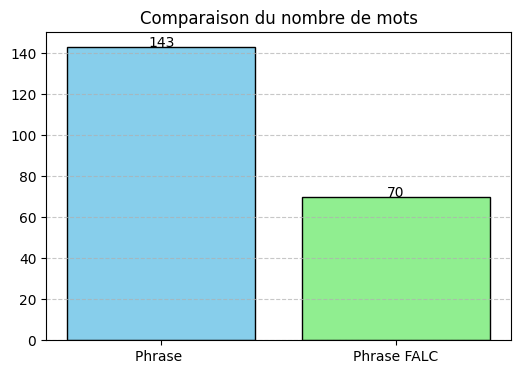

In [ ]:
#Texte compliqué
text = "Au cours des années 1920, durant des fouilles réalisées dans un cimetière de Haute-Égypte, des chercheurs ont trouvé dans une sépulture un petit objet métallique dont la nature et la fonction n'avaient visiblement rien d'évident. Environ un siècle plus tard, raconte The Debrief, la science a enfin compris la raison d'être de cet artefact datant de la période prédynastique de l'Égypte, une ère reculée antérieure au règne des premiers pharaons. Mesurant moins de 6,4 centimètres de diamètre et pesant moins de 2 grammes, cet objet fait d'un alliage de cuivre aurait été fabriqué il y a environ 5.300 ans. Selon des archéologues qui ont exposé le fruit de leurs recherches dans la revue Egypt and the Levant, il s'agit en fait d'un «outil de forage mécaniquement sophistiqué». Autrement dit, il y a plus de cinq millénaires, les Égyptiens avaient déjà inventé la perceuse."
mots = text.split()
nb_mots = len(mots) - (mots.count(".") + mots.count("!") + mots.count("?"))
nb_phrases = mots.count(".") + mots.count("!") + mots.count("?")

print(f"Number of words: {nb_mots}")
print(f"Number of punctuation marks: {nb_phrases}")


#On simplifie en FALC
result = falc_generation2(text, "models/falc_final")

mots_falc = result.split()
nb_mots_falc = len(mots_falc) - (mots_falc.count(".") + mots_falc.count("!") + mots_falc.count("?"))
nb_phrases_falc = mots.count(".") + mots.count("!") + mots.count("?")

print(f"Number of words after FALC simplification: {nb_mots_falc}")
print(f"Number of punctuation marks after FALC simplification: {nb_phrases_falc}")

label = ["Texte d'origine", "Texte FALC"]
values = [nb_mots, nb_mots_falc]
plt.figure(figsize=(6, 4))
plt.bar(label, values, color=['skyblue', 'lightgreen'], edgecolor='black')

# Annotate bars with values
for i, val in enumerate(values):
    plt.text(i, val + 0.1, str(val), ha='center', fontsize=10)

# Show grid for better readability
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.title("Comparaison du nombre de mots - T5-base")
plt.show()